# 01 - Data understanding

## 1. Loading

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # to import src from the notebooks folder

import pandas as pd
from src import config, data_loading as dl, audit as au, plots as pl

pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 60)
print("raw file:", config.RAW_FILE.name)

raw file: incident_event_log.csv


In [2]:
df = dl.load_raw()
print("rows:", df.shape[0], "| columns:", df.shape[1])
print(f"memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
df.dtypes.value_counts()

rows: 141712 | columns: 36
memory: 189.7 MB


object            24
datetime64[ns]     5
bool               4
int64              3
Name: count, dtype: int64

In [3]:
df.head(8)

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 21,2016-02-29 01:23:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 56,NaN,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,2016-02-29 11:29:00,2016-03-05 12:00:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 642,2016-02-29 08:53:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 56,NaN,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,2016-02-29 11:29:00,2016-03-05 12:00:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 804,2016-02-29 11:29:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 56,NaN,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,2016-02-29 11:29:00,2016-03-05 12:00:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,2016-02-29 01:16:00,Created by 6,2016-02-29 01:23:00,Updated by 908,2016-03-05 12:00:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 56,NaN,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,2016-02-29 11:29:00,2016-03-05 12:00:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 746,2016-02-29 04:57:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 89,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 81,2016-03-01 09:52:00,2016-03-06 10:00:00
5,INC0000047,Active,True,1,0,1,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 21,2016-02-29 05:30:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 24,Resolver 31,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 81,2016-03-01 09:52:00,2016-03-06 10:00:00
6,INC0000047,Active,True,1,0,2,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 21,2016-02-29 05:33:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 24,Resolver 31,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 81,2016-03-01 09:52:00,2016-03-06 10:00:00
7,INC0000047,Active,True,1,0,3,True,Caller 2403,Opened by 397,2016-02-29 04:40:00,Created by 171,2016-02-29 04:57:00,Updated by 804,2016-02-29 11:31:00,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,NaN,2 - Medium,2 - Medium,3 - Moderate,Group 24,Resolver 31,True,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 81,2016-03-01 09:52:00,2016-03-06 10:00:00


One row is one event of an incident (a state change or an update), not one incident. The same `number` appears on several rows and most columns repeat from one row to the next.

## 2. File integrity

In [4]:
import csv

# each line must have as many fields as the header
with open(config.RAW_FILE, newline="") as f:
    reader = csv.reader(f, delimiter=config.CSV_SEPARATOR)
    header = next(reader)
    widths = pd.Series([len(r) for r in reader])
print("fields in header:", len(header))
print("data lines read:", len(widths))
print("lines with a different number of fields:", int((widths != len(header)).sum()))

raw = dl.read_raw_text()
print("\nempty strings in the raw file:", int((raw == "").sum().sum()))
print("'?' cells in the raw file:", int((raw == "?").sum().sum()))
other = raw.isin(["NA", "N/A", "nan", "NaN", "null", "NULL", "None", "none", "-"]).sum().sum()
print("other missing-like markers (NA, null, none, -):", int(other))

fields in header: 36
data lines read: 141712
lines with a different number of fields: 0

empty strings in the raw file: 0
'?' cells in the raw file: 894597
other missing-like markers (NA, null, none, -): 0


In [5]:
# raw date strings
for c in config.DATE_COLS:
    s = raw[c][raw[c] != "?"]
    print(f"{c:15s} examples: {s.iloc[0]!r}, {s.iloc[-1]!r} | lengths: {sorted(s.str.len().unique())}")

opened_at       examples: '29/2/2016 01:16', '16/2/2017 14:17' | lengths: [np.int64(14), np.int64(15), np.int64(16)]
sys_created_at  examples: '29/2/2016 01:23', '27/1/2017 16:59' | lengths: [np.int64(14), np.int64(15), np.int64(16)]
sys_updated_at  examples: '29/2/2016 01:23', '16/2/2017 16:38' | lengths: [np.int64(14), np.int64(15), np.int64(16)]
resolved_at     examples: '29/2/2016 11:29', '16/2/2017 16:38' | lengths: [np.int64(14), np.int64(15), np.int64(16)]
closed_at       examples: '5/3/2016 12:00', '16/2/2017 16:38' | lengths: [np.int64(14), np.int64(15), np.int64(16)]


The file is a clean CSV: every line has 36 fields, there is no empty string, and `?` is the only missing marker (894,597 cells). Dates look like `29/2/2016 01:16`: day/month/year, with or without zero padding. `load_raw` parses them with the explicit format `%d/%m/%Y %H:%M` and raises an error if a value does not match. It ran without error, so all the dates are valid.

## 3. Incident identifier

In [6]:
ids = df[config.ID_COL]
events = au.events_per_incident(df)
print("distinct values of `number`:", ids.nunique())
print("all ids match INC + 7 digits:", bool(ids.str.fullmatch(r"INC\d{7}").all()))
print("events per incident: min", events.min(), "| median", events.median(), "| max", events.max())
nums = ids.drop_duplicates().str[3:].astype(int)
print("id range:", ids.iloc[0], "->", ids.iloc[-1], "| ids actually present:", len(nums), "of", nums.max() - nums.min() + 1, "numbers in the range")

# other columns that could be an id
cand = pd.DataFrame({"n_unique": df[["number", "caller_id", "opened_by", "opened_at", "sys_created_at"]].nunique()})
cand

distinct values of `number`: 24918
all ids match INC + 7 digits: True
events per incident: min 2 | median 5.0 | max 58
id range: INC0000045 -> INC0121064 | ids actually present: 24918 of 121020 numbers in the range


,n_unique
number,24918
caller_id,5244
opened_by,207
opened_at,19849
sys_created_at,11552


`number` behaves like an incident id: same format everywhere (INC + 7 digits), the rows of an incident are together, and every incident has at least 2 events (up to 58). There are 24,918 distinct ids, as in the documentation. No other column has as many distinct values (`caller_id` has 5,244).

Only about 21% of the numbers between `INC0000045` and `INC0121064` are in the file, so the ids are not continuous. I don't know why, so I don't treat the gaps as lost incidents.

## 4. File order and the last incident

In [7]:
checks = pd.Series(au.file_order_checks(df), name="result")
checks.to_frame()

,result
incident ids are in contiguous blocks,True
incident numbers increase through the file,True
opened_at increases through the file (incident level),True
incidents where sys_updated_at goes backwards,1
incidents where sys_mod_count is not increasing,4
incidents with a repeated sys_mod_count,5
incidents whose first event has sys_mod_count != 0,5


incidents opened from 2016-02-29 01:16:00 to 2017-02-16 14:17:00
days covered by opened_at: 354
share of incidents by opening month:
opened_at
2016-02    0.008
2016-03    0.361
2016-04    0.318
2016-05    0.301
2016-06    0.000
2016-07    0.001
2016-08    0.001
2016-09    0.000
2016-10    0.001
2016-11    0.001
2016-12    0.001
2017-01    0.004
2017-02    0.002
Freq: M


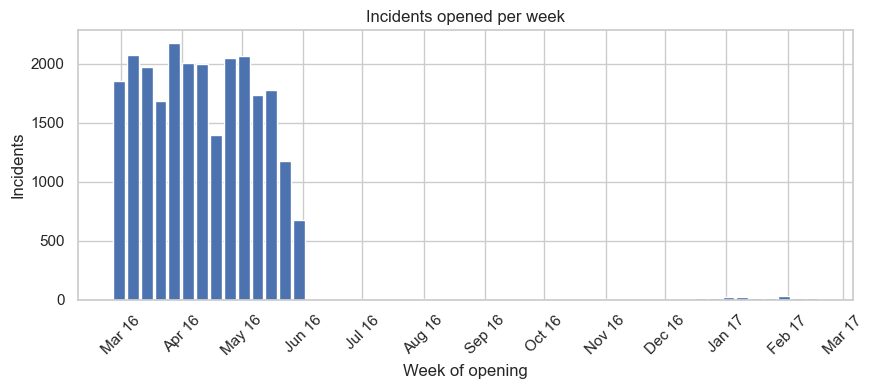

In [8]:
opened = df.groupby(config.ID_COL, sort=False)["opened_at"].first()
print("incidents opened from", opened.min(), "to", opened.max())
print("days covered by opened_at:", (opened.max().normalize() - opened.min().normalize()).days + 1)
print("share of incidents by opening month:")
print(opened.dt.to_period("M").value_counts(normalize=True).sort_index().round(3).to_string())
pl.plot_incidents_per_week(opened);

The file is sorted by incident number, and the numbers increase with the opening date (see the checks above). Inside incidents there are a few small order problems: 1 incident where `sys_updated_at` goes backwards and 4 where `sys_mod_count` is not increasing. They are looked at in notebook 02.

Opening dates go from 29 Feb 2016 to 16 Feb 2017, but about 99% of the incidents are opened between 29 Feb and 31 May 2016 (March 36.1%, April 31.8%, May 30.1%). Each month after May has 0.4% or less. So in practice the data covers about three months, with a thin tail afterwards. This matters for a time-based split later.

The chart shows the number of incidents opened each week.

In [9]:
display(au.last_incident(df))
print("state of the last event, all incidents:")
au.final_state_counts(df)

,incident_state,active,sys_mod_count,sys_updated_at,resolved_at,closed_at
141708,Active,True,0,2017-02-16 14:17:00,2017-02-16 16:38:00,2017-02-16 16:38:00
141709,Active,True,1,2017-02-16 15:20:00,2017-02-16 16:38:00,2017-02-16 16:38:00
141710,Resolved,True,2,2017-02-16 16:38:00,2017-02-16 16:38:00,2017-02-16 16:38:00
141711,Closed,False,3,2017-02-16 16:38:00,2017-02-16 16:38:00,2017-02-16 16:38:00


state of the last event, all incidents:


incident_state
Closed    24918
Name: count, dtype: int64

The last incident (`INC0121064`) has 4 events and ends in `Closed`. All 24,918 incidents have `Closed` as last event, so no incident is cut at the end of the file. The order of the events inside an incident is stable but not perfect.

## 5. Meaning of each column

In [10]:
info = pd.DataFrame(config.COLUMN_INFO, index=["group", "meaning"]).T
info["dtype"] = df.dtypes.astype(str)
info = info[["group", "dtype", "meaning"]]
info.groupby("group").size().to_frame("n_columns").T

group,classification,closure,counter,date,identifier,indicator,link,people/groups,state
n_columns,9,2,3,5,1,4,4,6,2


In [11]:
info

,group,dtype,meaning
number,identifier,object,Incident identifier (INCxxxxxxx). Repeated on every even...
incident_state,state,object,"State of the incident at this event (New, Active, Resolv..."
active,state,bool,Flag: the record is still active (False once the inciden...
reassignment_count,counter,int64,Number of times the incident was reassigned so far.
reopen_count,counter,int64,Number of times the incident was reopened so far.
sys_mod_count,counter,int64,Number of times the record was updated so far.
made_sla,indicator,bool,Flag: the SLA target was met.
caller_id,people/groups,object,Person who reported the incident (anonymised).
opened_by,people/groups,object,Person who opened the incident (anonymised).
opened_at,date,datetime64[ns],Date and time the incident was opened.


## 6. Dates

In [12]:
dates = au.date_ranges(df)
dates["n_missing"] = df[config.DATE_COLS].isna().sum()
dates["meaning"] = [config.COLUMN_INFO[c][1] for c in dates.index]
dates

,min,max,n_missing,meaning
opened_at,2016-02-29 01:16:00,2017-02-16 14:17:00,0,Date and time the incident was opened.
sys_created_at,2016-02-29 01:23:00,2017-01-27 16:59:00,53076,Date and time the record was created in the system.
sys_updated_at,2016-02-29 01:23:00,2017-02-18 15:00:00,0,Date and time of this update (time of the event).
resolved_at,2016-02-29 09:04:00,2017-02-17 00:47:00,3141,Date and time the incident was resolved.
closed_at,2016-02-29 17:47:00,2017-02-18 15:00:00,0,Date and time the incident was closed.


Five dates are available. `opened_at` is the start of the target, `resolved_at` and `closed_at` are the possible ends, and `sys_created_at` / `sys_updated_at` come from the system record.

Opening dates stop on 16 Feb 2017, but `sys_updated_at` and `closed_at` go up to 18 Feb 2017 and `resolved_at` to 17 Feb 2017. Only `sys_created_at` (53,076 events) and `resolved_at` (3,141 events) have missing values.

## 7. Known at opening or not? (first guess)

In [13]:
stab = au.column_stability(df)
cls = pd.DataFrame(config.AVAILABILITY, index=["availability", "reason", "planned use"]).T
cls = cls.join(stab[["pct_any_change", "pct_missing_first", "pct_missing_last"]])
cls = cls.loc[df.columns]
cls[["availability", "pct_any_change", "pct_missing_first", "pct_missing_last", "reason"]]

,availability,pct_any_change,pct_missing_first,pct_missing_last,reason
number,known at opening,NaN,NaN,NaN,Identifier of the incident.
incident_state,known only after opening (leakage risk),100.00,0.00,0.00,"Changes at every event, it follows the progress of the i..."
active,known only after opening (leakage risk),100.00,0.00,0.00,Turns False when the incident is closed.
reassignment_count,known only after opening (leakage risk),45.63,0.00,0.00,Counter that grows while the incident is handled.
reopen_count,known only after opening (leakage risk),1.10,0.00,0.00,Counter that grows after a resolution.
sys_mod_count,known only after opening (leakage risk),100.00,0.00,0.00,"Counter of updates, it grows during the life of the inci..."
made_sla,known only after opening (leakage risk),36.58,0.00,0.00,"SLA result, linked to how long the incident took."
caller_id,known at opening,0.01,0.01,0.01,The caller exists when the incident is opened.
opened_by,known at opening,0.00,2.87,2.87,The person who opens the incident is known at opening.
opened_at,known at opening,0.00,0.00,0.00,"Opening time, start of the target."


In [14]:
cls.groupby('availability').size().to_frame('n_columns')

,n_columns
availability,
known at opening,6
known only after opening (leakage risk),19
maybe known at opening,11


How to read the table: `pct_any_change` is the share of incidents where the value is not the same on all events. A column that changes during the life of an incident cannot be taken as known at opening unless I choose the right event. `pct_missing_first` and `pct_missing_last` compare the missing rate on the first and on the last event.

What I see:
- Stable columns: `opened_at`, `opened_by`, `contact_type`, `notify`, `caller_id`. They are the safest candidates.
- Columns that change a lot: `incident_state`, `active`, `sys_mod_count`, `sys_updated_at`, `u_priority_confirmation` (76.8%), `reassignment_count` (45.6%), `assignment_group` (45.5%), `made_sla` (36.6%). They follow the progress of the incident, so they are known only after opening.
- `assigned_to` is empty on 28.7% of first events and 2.9% of last events. This fits with "assigned while the incident is handled".
- `category`, `subcategory`, `u_symptom`, `impact`, `urgency` and `priority` change in a minority of incidents (1.2% to 7.4%). Their value at opening is probably available, but it may be corrected later.

Careful: stable does not mean known at opening. `resolved_at`, `closed_at`, `closed_code` and `resolved_by` never change inside an incident, but they are closure information. They are already filled on the first event for most incidents (`resolved_at` for 93.8%, `closed_at` for 100%), so reading the first row of an incident would leak the future.

In [15]:
# share of events where the resolution / closure date is later than the event itself
future = pd.DataFrame({
    "resolved_at after the event time": [(df["resolved_at"] > df["sys_updated_at"]).mean()],
    "closed_at after the event time": [(df["closed_at"] > df["sys_updated_at"]).mean()],
}, index=["share of all events"]) * 100
first, _ = au.first_last_events(df)
future.loc["share of first events"] = [
    (first["resolved_at"] > first["sys_updated_at"]).mean() * 100,
    (first["closed_at"] > first["sys_updated_at"]).mean() * 100,
]
future.round(1)

,resolved_at after the event time,closed_at after the event time
share of all events,61.7,82.4
share of first events,91.9,100.0


61.7% of all events carry a resolution date that is later than the event itself, and 82.4% carry a later closure date. On the first event of an incident it is 91.9% and 100%. The log is "enriched": the final values are copied on every row. This is the main leakage risk of the project. The incident table must be built with a clear rule per column (notebook 03), never with a simple first or last row.

## Decisions

- Use the CSV as it is: `?` becomes missing, dates are parsed with `%d/%m/%Y %H:%M`, nothing is dropped.
- `number` is the incident identifier. Grouping and splitting are done on it.
- Keep the classification of `config.AVAILABILITY` as a first guess. The columns known only after opening are excluded from the main model.
- Never build the incident table from the first or last row without checking what that row contains.
